# Routing Cost of Upfront Exit Prediction versus Reactive Confidence Gating on a Four-Exit YOLOv8x (BDD100K)

This notebook measures the **computational cost of the exit decision** in a four-exit YOLOv8x detector: per-frame latency, GPU energy, GFLOPs, activated parameters and decision overhead. Detection accuracy is not measured.

**Detector.** One YOLOv8x backbone with four exits, using the exit heads of the UEPNet experiments: **Exit 1** (layer 6, single-scale P4 head), **Exit 2** (dual-scale P3+P4 head), **Exit 3** (partial neck: top-down path + Detect(P3, P4, P5)) and the **Final Exit** (full YOLOv8x neck). All exits share one trunk. The YOLOv8x weights are randomly initialised, and BatchNorm statistics are recalibrated on BDD100K frames. Weights do not change FLOPs, parameters or kernel shapes. NMS receives the same top-K candidates at every exit for every method, with K measured on the trained YOLOv8m detector.

**Methods.**

| Method | Decision mechanism |
|---|---|
| **ReactiveConf** | Sequential cascade. Each exit is evaluated in turn, and its confidence (1 − mean binary entropy of the top-100 raw class scores, computed before NMS) decides whether to stop. NMS runs only at the exit taken. Exit 3 reuses the final model's top-down neck, so escalating from Exit 3 to the Final Exit runs only the remaining layers. This is the strongest cascade configuration. |
| **UEP1** | Upfront Exit Predictor (MobileNetV3-Small, one output per exit) evaluated on the raw image of **every** frame. The backbone runs only as deep as the predicted exit, and only that exit's head is executed. |
| **UEP3** / **UEP5** | The same predictor evaluated once every 3 / 5 frames; intermediate frames reuse the last decision. |
| **Free Routing** | Direct execution of the assigned exit with no decision cost. This is the lower bound used to measure decision overhead. |

**Protocol.**

* **Per-exit image sets.** The timed BDD100K test images are split at random into four equal, disjoint sets, one per exit. Every method takes the same exit on the same images, so detection output is identical across methods by construction, and the methods differ only in the cost of deciding.
* **Execution.** Each method runs at batch 1 in FP16 on one GPU. Every fixed-shape block (preprocessing, trunk, exit heads and the UEP) is executed as a CUDA graph for all methods alike. NMS and confidence checks run eagerly.
* **Aggregates.** The **equal split** pools the four sets with equal weight, so each exit receives 25% of the frames.
* **Decision overhead** of a method is its per-frame latency minus Free Routing's latency on the same images.

## 1. Inputs and environment
Attach **`bdd100k_75_25_experiment`** and the BDD100K YOLO-format dataset as Kaggle inputs. Nothing is trained.

In [1]:
import os
os.environ.setdefault('CUDA_DEVICE_ORDER', 'PCI_BUS_ID')   # cuda:0 and NVML device 0 = same physical GPU
from pathlib import Path

INPUT_ROOT = Path(os.environ.get('KAGGLE_INPUT_ROOT', '/kaggle/input'))
WORK_ROOT = Path(os.environ.get('KAGGLE_WORK_ROOT', '/kaggle/working'))


def find_named_dir(root, name, max_depth=5, skip=('images', 'labels')):
    root = Path(root)
    if not root.is_dir():
        return []
    found = []
    for current, dirs, _ in os.walk(root):
        depth = Path(current).relative_to(root).parts
        if Path(current).name == name:
            found.append(Path(current))
            dirs[:] = []
            continue
        if len(depth) >= max_depth:
            dirs[:] = []
            continue
        dirs[:] = [d for d in dirs if d not in skip]
    return found


matches = find_named_dir(INPUT_ROOT, 'bdd100k_75_25_experiment')
if not matches and (WORK_ROOT / 'bdd100k_75_25_experiment').is_dir():
    matches = [WORK_ROOT / 'bdd100k_75_25_experiment']
SOURCE_EXPERIMENT_DIR = matches[0] if matches else None
if SOURCE_EXPERIMENT_DIR is None:
    print('WARNING: bdd100k_75_25_experiment not found. Falling back to a random-init UEP and a default NMS load.')
else:
    print(f'Experiment artifacts (read-only): {SOURCE_EXPERIMENT_DIR}')

Experiment artifacts (read-only): /kaggle/input/datasets/saathvik16/bdd100k-experiment-checkpoint/bdd100k_75_25_experiment


In [2]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('ultralytics') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'ultralytics'])
else:
    print('Using the preinstalled Ultralytics.')
if importlib.util.find_spec('pynvml') is None:
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'nvidia-ml-py'])
    except Exception as err:
        print(f'Could not install nvidia-ml-py ({err}); GPU energy will be unavailable.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.3 MB/s eta 0:00:00


In [3]:
import copy
import json
import logging
import math
import random
import threading
import time
from datetime import datetime, timezone

import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import yaml
from torch.utils.flop_counter import FlopCounterMode
from torchvision import models
from tqdm.auto import tqdm
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils.ops import scale_boxes

try:
    from IPython.display import display
except ImportError:
    display = print

import ultralytics
print(f'torch {torch.__version__} | ultralytics {ultralytics.__version__} | numpy {np.__version__}')

# ----------------------------- Experiment configuration -----------------------------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

HAS_CUDA = torch.cuda.is_available()
DEVICE = torch.device('cuda:0' if HAS_CUDA else 'cpu')
USE_HALF = HAS_CUDA                 # FP16 for every GPU block (YOLO and UEP alike)
ENGINE = 'graphed' if HAS_CUDA else 'eager'   # 'graphed': CUDA graphs for every fixed-shape block, all methods
MODEL_SCALE = 'x'                   # YOLOv8x
NC = 10
IMAGE_SIZE = 640
LETTERBOX_STRIDE = 32               # 1280x720 -> 640x384 (Ultralytics predict default, auto=True)

NMS_IOU = 0.7
MAX_DET = 300
NMS_TOPK_DEFAULT = 1000             # used only if the trained YOLOv8m detector is unavailable
NMS_CALIB_IMAGES = 64
NMS_CALIB_CONF = 0.05
PRE_NMS_TOPK = 100                  # ReactiveConf confidence uses the top-100 raw class scores

UEP_OUTPUTS = 4                     # one sufficiency score per exit
BN_CALIB_IMAGES = 64
BN_CALIB_BATCH = 8
CALIB_FRACTION = 0.30

PROFILE_N = 200                     # images for per-block latency profiling (latency breakdown)
WARMUP_ITERS = 30
LATENCY_N = 4000                    # timed test images: 4 equal per-exit sets of 1000
LATENCY_CHUNK = 250
LATENCY_WARMUP_PER_CONFIG = 5
IDLE_SECONDS = 5.0
BOOTSTRAP_ITERS = 2000

# Nomenclature used in every figure and table.
METHODS = ['ReactiveConf', 'UEP1', 'UEP3', 'UEP5', 'Free Routing']
METHOD_SPEC = {'ReactiveConf': ('reactiveconf', 1), 'UEP1': ('uep', 1), 'UEP3': ('uep', 3), 'UEP5': ('uep', 5),
               'Free Routing': ('free', 1)}
EXIT_LABELS = {'E1': 'Exit 1', 'E2': 'Exit 2', 'E3': 'Exit 3', 'F': 'Final Exit'}

if os.environ.get('UEP_SMOKE_TEST') == '1' or not HAS_CUDA:
    PROFILE_N, WARMUP_ITERS, LATENCY_N, LATENCY_CHUNK, LATENCY_WARMUP_PER_CONFIG = 3, 1, 8, 2, 1
    BN_CALIB_IMAGES, BN_CALIB_BATCH, NMS_CALIB_IMAGES, BOOTSTRAP_ITERS = 4, 2, 2, 50
    print('SMOKE-TEST SIZES ACTIVE (no CUDA or UEP_SMOKE_TEST=1). Numbers are not meaningful.')

OUT_DIR = WORK_ROOT / 'uep_vs_reactiveconf_yolov8x'
FIG_DIR, TABLE_DIR = OUT_DIR / 'figures', OUT_DIR / 'tables'
for d in (OUT_DIR, FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

torch.backends.cudnn.benchmark = True
if HAS_CUDA:
    print(f'GPU: {torch.cuda.get_device_name(DEVICE)} | CPU threads: {os.cpu_count()}')
print(f'Execution: {ENGINE} | outputs: {OUT_DIR}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
torch 2.11.0+cu128 | ultralytics 8.4.182 | numpy 2.1.3
GPU: Tesla T4 | CPU threads: 4
Execution: graphed | outputs: /kaggle/working/uep_vs_reactiveconf_yolov8x


In [4]:
# ---------------- Figure style (default matplotlib font) ----------------
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
mpl.rcParams.update({
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'normal',
    'axes.labelsize': 10, 'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9,
    'axes.edgecolor': '#333333', 'axes.linewidth': 0.8, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#dddddd', 'grid.linewidth': 0.6, 'xtick.direction': 'out', 'ytick.direction': 'out',
    'legend.frameon': True, 'legend.framealpha': 0.95, 'legend.edgecolor': '#bbbbbb', 'legend.fancybox': False,
    'lines.linewidth': 1.6, 'lines.markersize': 5, 'figure.dpi': 120, 'savefig.dpi': 300,
    'savefig.bbox': 'tight', 'pdf.fonttype': 42, 'ps.fonttype': 42,
})
# Okabe-Ito colour-blind-safe palette; one fixed colour and marker per method in every figure.
METHOD_COLORS = {'ReactiveConf': '#D55E00', 'UEP1': '#0072B2', 'UEP3': '#009E73', 'UEP5': '#CC79A7',
                 'Free Routing': '#4D4D4D'}
METHOD_MARKERS = {'ReactiveConf': 's', 'UEP1': 'o', 'UEP3': '^', 'UEP5': 'D', 'Free Routing': ''}
COMPONENT_COLORS = {'Backbone/Detector': '#7F7F7F', 'Decision Check/UEP': '#E69F00'}


def savefig(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')
    fig.savefig(FIG_DIR / f'{name}.pdf')
    plt.show()
    plt.close(fig)

## 2. BDD100K and the calibration/test split
The BDD100K validation images are split at random (seed 42) into a 30% calibration split and a 70% test split. The calibration split is used only for BatchNorm recalibration and for measuring the NMS load. Every timed frame comes from the test split.

In [5]:
BDD100K_ROOT = None
_candidates = [Path(os.environ['BDD100K_ROOT'])] if os.environ.get('BDD100K_ROOT') else []
_candidates += [INPUT_ROOT / 'bdd100k-object-dection-with-yolo-format-labels' / '100k-dataset',
                INPUT_ROOT / 'datasets' / 'saathvik16' / 'bdd100k-object-dection-with-yolo-format-labels' / '100k-dataset']
_candidates += find_named_dir(INPUT_ROOT, '100k-dataset', max_depth=5)
for _c in _candidates:
    if (_c / 'val' / 'images').is_dir():
        BDD100K_ROOT = _c.resolve()
        break
if BDD100K_ROOT is None:
    try:
        import kagglehub
        _p = Path(kagglehub.dataset_download('saathvik16/bdd100k-object-dection-with-yolo-format-labels'))
        BDD100K_ROOT = (_p / '100k-dataset') if (_p / '100k-dataset').is_dir() else _p
    except Exception as err:
        raise FileNotFoundError(f'Could not locate BDD100K ({err}). Attach the YOLO-format BDD100K dataset.')
VAL_IMAGES_DIR = BDD100K_ROOT / 'val' / 'images'
IMAGE_SUFFIXES = {'.bmp', '.jpeg', '.jpg', '.png', '.webp'}
VAL_IMAGE_PATHS = sorted(p for p in VAL_IMAGES_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
VAL_NAMES = [p.name for p in VAL_IMAGE_PATHS]
N_VAL = len(VAL_IMAGE_PATHS)
print(f'BDD100K: {BDD100K_ROOT} | val images: {N_VAL}')

_rng = np.random.default_rng(SEED)
_perm = _rng.permutation(N_VAL)
_n_cal = int(round(CALIB_FRACTION * N_VAL))
CALIB_IDX, TEST_IDX = np.sort(_perm[:_n_cal]), np.sort(_perm[_n_cal:])
print(f'Calibration: {len(CALIB_IDX)} | Test: {len(TEST_IDX)} (same seed and split as the YOLOv8m notebook)')

_shape = cv2.imread(str(VAL_IMAGE_PATHS[int(TEST_IDX[0])])).shape
FRAME_SHAPE = _shape[:2]
print(f'Reference frame shape: {FRAME_SHAPE} (CUDA graphs are captured for this shape; any other shape falls back to eager)')

BDD100K: /kaggle/input/datasets/saathvik16/bdd100k-object-dection-with-yolo-format-labels/100k-dataset | val images: 10000
Calibration: 3000 | Test: 7000 (same seed and split as the YOLOv8m notebook)
Reference frame shape: (720, 1280) (CUDA graphs are captured for this shape; any other shape falls back to eager)


## 3. The four-exit YOLOv8x
The exit heads use the UEPNet early-exit YAML definitions with the scale set to `x`. The final model's backbone weights are copied into every exit, so one trunk pass serves all four exits.

In [6]:
SCALES_YAML = """
scales:
  n: [0.33, 0.25, 1024]
  s: [0.33, 0.50, 1024]
  m: [0.67, 0.75, 768]
  l: [1.00, 1.00, 512]
  x: [1.00, 1.25, 512]
"""

YAML_E1 = """nc: 10
""" + SCALES_YAML + """
backbone:
  - [-1, 1, Conv, [64, 3, 2]]      # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]     # 1-P2/4
  - [-1, 3, C2f, [128, True]]      # 2
  - [-1, 1, Conv, [256, 3, 2]]     # 3-P3/8
  - [-1, 6, C2f, [256, True]]      # 4
  - [-1, 1, Conv, [512, 3, 2]]     # 5-P4/16
  - [-1, 6, C2f, [512, True]]      # 6 <- EXIT POINT
head:
  - [-1, 1, Conv, [256, 3, 1]]     # 7 - reduce channels
  - [-1, 1, Conv, [256, 3, 1]]     # 8 - feature refinement
  - [-1, 1, Conv, [128, 1, 1]]     # 9 - further channel reduction
  - [[9], 1, Detect, [nc]]         # 10 - Detect head (single scale P4)
"""

YAML_E2 = """nc: 10
""" + SCALES_YAML + """
backbone:
  - [-1, 1, Conv, [64, 3, 2]]      # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]     # 1-P2/4
  - [-1, 3, C2f, [128, True]]      # 2
  - [-1, 1, Conv, [256, 3, 2]]     # 3-P3/8
  - [-1, 6, C2f, [256, True]]      # 4 <- P3 features
  - [-1, 1, Conv, [512, 3, 2]]     # 5-P4/16
  - [-1, 6, C2f, [512, True]]      # 6 <- EXIT POINT
head:
  - [-1, 1, Conv, [384, 3, 1]]     # 7 - reduce channels
  - [-1, 1, Conv, [384, 3, 1]]     # 8 - refine features
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 9
  - [[-1, 4], 1, Concat, [1]]                   # 10 - cat P3 from layer 4
  - [-1, 2, C2f, [256]]                         # 11 - process P3
  - [8, 1, Conv, [512, 3, 1]]                   # 12 - final P4 refinement
  - [[11, 12], 1, Detect, [nc]]                 # 13 - Detect(P3, P4)
"""

YAML_E3 = """nc: 10
""" + SCALES_YAML + """
backbone:
  - [-1, 1, Conv, [64, 3, 2]]      # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]     # 1-P2/4
  - [-1, 3, C2f, [128, True]]      # 2
  - [-1, 1, Conv, [256, 3, 2]]     # 3-P3/8
  - [-1, 6, C2f, [256, True]]      # 4
  - [-1, 1, Conv, [512, 3, 2]]     # 5-P4/16
  - [-1, 6, C2f, [512, True]]      # 6
  - [-1, 1, Conv, [1024, 3, 2]]    # 7-P5/32
  - [-1, 3, C2f, [1024, True]]     # 8
  - [-1, 1, SPPF, [1024, 5]]       # 9
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 10
  - [[-1, 6], 1, Concat, [1]]                   # 11 - cat P4
  - [-1, 3, C2f, [512]]                         # 12
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 13
  - [[-1, 4], 1, Concat, [1]]                   # 14 - cat P3
  - [-1, 3, C2f, [256]]                         # 15
  - [[15, 12, 9], 1, Detect, [nc]]              # 16 - Detect(P3, P4, P5)
"""

YAML_FINAL = """nc: 10
""" + SCALES_YAML + """
backbone:
  - [-1, 1, Conv, [64, 3, 2]]      # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]     # 1-P2/4
  - [-1, 3, C2f, [128, True]]      # 2
  - [-1, 1, Conv, [256, 3, 2]]     # 3-P3/8
  - [-1, 6, C2f, [256, True]]      # 4
  - [-1, 1, Conv, [512, 3, 2]]     # 5-P4/16
  - [-1, 6, C2f, [512, True]]      # 6
  - [-1, 1, Conv, [1024, 3, 2]]    # 7-P5/32
  - [-1, 3, C2f, [1024, True]]     # 8
  - [-1, 1, SPPF, [1024, 5]]       # 9
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 10
  - [[-1, 6], 1, Concat, [1]]                   # 11 - cat backbone P4
  - [-1, 3, C2f, [512]]                         # 12
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]  # 13
  - [[-1, 4], 1, Concat, [1]]                   # 14 - cat backbone P3
  - [-1, 3, C2f, [256]]                         # 15 (P3/8-small)
  - [-1, 1, Conv, [256, 3, 2]]                  # 16
  - [[-1, 12], 1, Concat, [1]]                  # 17 - cat head P4
  - [-1, 3, C2f, [512]]                         # 18 (P4/16-medium)
  - [-1, 1, Conv, [512, 3, 2]]                  # 19
  - [[-1, 9], 1, Concat, [1]]                   # 20 - cat head P5
  - [-1, 3, C2f, [1024]]                        # 21 (P5/32-large)
  - [[15, 18, 21], 1, Detect, [nc]]             # 22 - Detect(P3, P4, P5)
"""

EXIT_YAMLS = {'E1': YAML_E1, 'E2': YAML_E2, 'E3': YAML_E3, 'F': YAML_FINAL}
EXIT_BRANCH = {'E1': 7, 'E2': 7, 'E3': 10, 'F': 10}      # first head layer index = number of shared trunk layers
EXIT_ORDER = ['E1', 'E2', 'E3', 'F']
for name, text in EXIT_YAMLS.items():
    (OUT_DIR / f'yolov8{MODEL_SCALE}_{name}.yaml').write_text(text)


def build_detection_model(yaml_text):
    cfg = yaml.safe_load(yaml_text)
    cfg['scale'] = MODEL_SCALE           # explicit: never rely on the file name to pick the scale
    return DetectionModel(cfg=cfg, ch=3, nc=NC, verbose=False)


torch.manual_seed(SEED)
raw = {name: build_detection_model(text) for name, text in EXIT_YAMLS.items()}
final_raw = raw['F']

# Structural check + copy the final model's backbone into every exit (shared trunk).
for name in ('E1', 'E2', 'E3'):
    for i in range(EXIT_BRANCH[name]):
        a, b = raw[name].model[i], final_raw.model[i]
        assert type(a) is type(b) and a.f == b.f, f'{name}: layer {i} differs from the final model'
        b_sd = b.state_dict()
        assert all(v.shape == b_sd[k].shape for k, v in a.state_dict().items()), f'{name}: layer {i} shapes differ'
        a.load_state_dict(b_sd)
# Head layers may only read shared trunk indices that are cached: 4, 6 (and 9 for E3/F).
for name in EXIT_ORDER:
    b = EXIT_BRANCH[name]
    for m in raw[name].model[b:]:
        refs = [m.f] if isinstance(m.f, int) else list(m.f)
        assert all(r == -1 or r >= b or r in (4, 6, 9) for r in refs), (name, m.i, m.f)
print('Exit structures verified; backbone weights shared.')


def count_params(mod):
    return sum(p.numel() for p in mod.parameters())


arch_rows = []
for name in EXIT_ORDER:
    m, b = raw[name], EXIT_BRANCH[name]
    arch_rows.append({'exit': name, 'branches after layer': b - 1, 'trunk params (M)': count_params(m.model[:b]) / 1e6,
                      'head params (M)': count_params(m.model[b:]) / 1e6, 'standalone model params (M)': count_params(m) / 1e6})
print(pd.DataFrame(arch_rows).round(3).to_string(index=False))

Exit structures verified; backbone weights shared.
exit  branches after layer  trunk params (M)  head params (M)  standalone model params (M)
  E1                     6            19.260            3.414                       22.674
  E2                     6            19.260           14.426                       33.686
  E3                     9            30.943           18.056                       48.999
   F                     9            30.943           37.219                       68.162


In [7]:
# ---------------- BatchNorm recalibration on real BDD100K frames ----------------
# Random-init conv weights + default BN statistics give activations far from a trained network's,
# which can overflow in FP16. We recompute every BN's running statistics on calibration frames
# (no gradients, no weight changes). Cost metrics are unaffected; numerics become realistic.
def letterbox_np(img, size=IMAGE_SIZE, stride=LETTERBOX_STRIDE):
    h0, w0 = img.shape[:2]
    r = min(size / h0, size / w0)
    nw, nh = int(round(w0 * r)), int(round(h0 * r))
    dw, dh = (size - nw) % stride / 2, (size - nh) % stride / 2
    im = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR) if (nw, nh) != (w0, h0) else img
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    im = cv2.copyMakeBorder(im, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))
    return torch.from_numpy(im[:, :, ::-1].transpose(2, 0, 1).copy()).float() / 255.0


_bn_idx = np.random.default_rng(SEED + 3).choice(CALIB_IDX, size=min(BN_CALIB_IMAGES, len(CALIB_IDX)), replace=False)
_bn_batches = [torch.stack([letterbox_np(cv2.imread(str(VAL_IMAGE_PATHS[i]))) for i in _bn_idx[s:s + BN_CALIB_BATCH]])
               for s in range(0, len(_bn_idx), BN_CALIB_BATCH)]


@torch.no_grad()
def recalibrate_bn(model, batches, device):
    model.to(device).float().train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats()
            m.momentum = None                 # cumulative average over all calibration batches
    for xb in batches:
        model(xb.to(device))
    model.eval().cpu()


_calib_dev = DEVICE
for name in tqdm(EXIT_ORDER, desc='BN recalibration'):
    recalibrate_bn(raw[name], _bn_batches, _calib_dev)
# Re-copy the final model's (recalibrated) trunk so all exits share bit-identical trunk weights and statistics.
for name in ('E1', 'E2', 'E3'):
    for i in range(EXIT_BRANCH[name]):
        raw[name].model[i].load_state_dict(final_raw.model[i].state_dict())
for m in raw.values():
    for p in m.parameters():
        p.requires_grad_(False)
print('BatchNorm statistics recalibrated on', len(_bn_idx), 'BDD100K calibration frames.')

BN recalibration:   0%|          | 0/4 [00:00<?, ?it/s]

BatchNorm statistics recalibrated on 64 BDD100K calibration frames.


In [8]:
# ---------------- NMS workload, anchored to the trained YOLOv8m on BDD100K ----------------
# With random weights the raw scores are meaningless, so a confidence threshold would give an unrealistic NMS
# input size. Instead, every exit and every method passes the same top-K candidates to NMS. K is the mean number of
# pre-NMS candidates above conf 0.05 produced by the TRAINED YOLOv8m detector of bdd100k_75_25_experiment.
NMS_TOPK, NMS_TOPK_SOURCE = NMS_TOPK_DEFAULT, 'default'
_det_w = None
if SOURCE_EXPERIMENT_DIR is not None:
    for _p in (SOURCE_EXPERIMENT_DIR / 'checkpoints' / 'yolov8m_detector' / 'weights' / 'best.pt',
               SOURCE_EXPERIMENT_DIR / 'checkpoints' / 'yolov8m_detector' / 'weights' / 'last.pt'):
        if _p.is_file():
            _det_w = _p
            break
if _det_w is not None:
    try:
        from ultralytics import YOLO
        _m8 = YOLO(str(_det_w)).model.float().eval().to(DEVICE)
        _counts = []
        with torch.no_grad():
            for i in np.random.default_rng(SEED + 4).choice(CALIB_IDX, size=min(NMS_CALIB_IMAGES, len(CALIB_IDX)), replace=False):
                _out = _m8(letterbox_np(cv2.imread(str(VAL_IMAGE_PATHS[i])))[None].to(DEVICE))
                _out = _out[0] if isinstance(_out, (list, tuple)) else _out
                _counts.append(int((_out[0, 4:].amax(0) > NMS_CALIB_CONF).sum()))
        NMS_TOPK, NMS_TOPK_SOURCE = int(round(np.mean(_counts))), f'trained YOLOv8m, mean candidates > {NMS_CALIB_CONF}'
        del _m8
    except Exception as err:
        print(f'Could not measure NMS load from the trained detector ({err}); using default.')
if NMS_TOPK < 50:
    print(f'Measured NMS load ({NMS_TOPK}) is implausibly small for a trained BDD100K detector; using the default.')
    NMS_TOPK, NMS_TOPK_SOURCE = NMS_TOPK_DEFAULT, 'default (measured value rejected)'
print(f'NMS input: top-{NMS_TOPK} candidates per exit ({NMS_TOPK_SOURCE}); IoU {NMS_IOU}; max_det {MAX_DET}')

NMS input: top-130 candidates per exit (trained YOLOv8m, mean candidates > 0.05); IoU 0.7; max_det 300


In [9]:
# ---------------- The multi-exit UEP (MobileNetV3-Small, 4 outputs) ----------------
# Same backbone as the UEP deployed with YOLOv8m; the regression head outputs one score per exit.
# The trained feature extractor is loaded when available (weights do not affect cost).
def build_uep():
    m = models.mobilenet_v3_small(weights=None)
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, UEP_OUTPUTS)
    return m


uep_raw = build_uep()
UEP_SOURCE = 'random init'
if SOURCE_EXPERIMENT_DIR is not None:
    for _p in (SOURCE_EXPERIMENT_DIR / 'models' / 'uep_mobilenet_v3_small.pth',
               SOURCE_EXPERIMENT_DIR / 'checkpoints' / 'uep' / 'mobilenet_v3_small' / 'best.pt'):
        if _p.is_file():
            try:
                _sd = torch.load(_p, map_location='cpu', weights_only=False)
            except TypeError:
                _sd = torch.load(_p, map_location='cpu')
            _sd = _sd.get('model_state_dict', _sd) if isinstance(_sd, dict) else _sd
            _sd = {k: v for k, v in _sd.items() if not k.startswith('classifier.3')}   # drop the 1-output layer
            missing, unexpected = uep_raw.load_state_dict(_sd, strict=False)
            UEP_SOURCE = f'trained BDD100K UEP features ({_p.name}); new {UEP_OUTPUTS}-way output layer'
            break
uep_raw.eval()
for p in uep_raw.parameters():
    p.requires_grad_(False)
print(f'UEP: {UEP_SOURCE} | params {count_params(uep_raw) / 1e6:.3f} M')

UEP: trained BDD100K UEP features (uep_mobilenet_v3_small.pth); new 4-way output layer | params 1.522 M


## 4. The multi-exit system
One object holds every compute block once: load/letterbox, trunk (layers 0–6), backbone tail (layers 7–9), the four exit heads, the shared-neck variants used by ReactiveConf, the UEP and NMS. With `ENGINE = 'graphed'`, each fixed-shape block is captured once as a CUDA graph and chained through static buffers.

In [10]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def pred_tensor(out):
    while isinstance(out, (list, tuple)):
        out = out[0]
    if isinstance(out, dict):                      # some Ultralytics versions return dicts
        out = out.get('one2many', out.get('one2one', next(iter(out.values()))))
        return pred_tensor(out)
    return out


def run_layers(layers, x, y):
    for m in layers:
        if m.f != -1:
            x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
        x = m(x)
        y.append(x)
    return x


def deploy_copy(model, device, half):
    m = copy.deepcopy(model)
    if hasattr(m, 'fuse'):
        m = m.fuse(verbose=False)
    m = m.to(device).eval()
    return m.half() if half else m.float()


class GraphBlock:
    # A CUDA-graph replay of fn(*static_inputs) -> tuple of tensors. Inputs are static buffers; if a caller passes a
    # different tensor it is copied in (chained blocks pass the producer's static output, so no copy happens).
    def __init__(self, fn, static_inputs, name):
        self.name, self.static_in = name, list(static_inputs)
        side = torch.cuda.Stream()
        side.wait_stream(torch.cuda.current_stream())
        with torch.cuda.stream(side):
            for _ in range(3):
                fn(*self.static_in)
        torch.cuda.current_stream().wait_stream(side)
        torch.cuda.synchronize()
        self.graph = torch.cuda.CUDAGraph()
        with torch.cuda.graph(self.graph):
            out = fn(*self.static_in)
        self.static_out = out if isinstance(out, tuple) else (out,)
        torch.cuda.synchronize()

    def __call__(self, *inputs):
        for s, t in zip(self.static_in, inputs):
            if t is not s:
                s.copy_(t)
        self.graph.replay()
        return self.static_out if len(self.static_out) > 1 else self.static_out[0]


class MultiExitSystem:
    def __init__(self, raw_models, uep_model, device, half):
        self.device = torch.device(device)
        self.is_cuda = self.device.type == 'cuda'
        self.dtype = torch.float16 if half else torch.float32
        d = {k: deploy_copy(m, device, half) for k, m in raw_models.items()}
        self.final = d['F']
        self.trunkA_layers = self.final.model[:7]
        self.trunkB_layers = self.final.model[7:10]
        self.head_layers = {k: d[k].model[EXIT_BRANCH[k]:] for k in EXIT_ORDER}
        self.e3_detect = d['E3'].model[-1]                 # Detect(15, 12, 9) on the shared top-down neck
        self.shared_neck = self.final.model[10:16]
        self.final_tail = self.final.model[16:]
        self.uep = deploy_copy(uep_model, device, half)
        self.mean = torch.tensor(IMAGENET_MEAN, device=self.device).view(1, 3, 1, 1)
        self.std = torch.tensor(IMAGENET_STD, device=self.device).view(1, 3, 1, 1)
        self.uep_tau = torch.full((UEP_OUTPUTS,), 0.5, device=self.device)
        self._lb = {}
        self.graphs = {}
        self.engine = 'eager'

    def sync(self):
        if self.is_cuda:
            torch.cuda.synchronize(self.device)

    # ---------------- eager block implementations ----------------
    def _upload(self, img):
        return torch.from_numpy(img).to(self.device)

    def _lb_params(self, h0, w0):
        if (h0, w0) not in self._lb:
            r = min(IMAGE_SIZE / h0, IMAGE_SIZE / w0)
            nw, nh = int(round(w0 * r)), int(round(h0 * r))
            dw, dh = (IMAGE_SIZE - nw) % LETTERBOX_STRIDE / 2, (IMAGE_SIZE - nh) % LETTERBOX_STRIDE / 2
            self._lb[(h0, w0)] = (nh, nw, int(round(dh - 0.1)), int(round(dh + 0.1)), int(round(dw - 0.1)), int(round(dw + 0.1)))
        return self._lb[(h0, w0)]

    def _pre(self, g):
        nh, nw, top, bottom, left, right = self._lb_params(*g.shape[:2])
        x = g.permute(2, 0, 1).unsqueeze(0).flip(1).float()
        if (nh, nw) != tuple(g.shape[:2]):
            x = F.interpolate(x, size=(nh, nw), mode='bilinear', align_corners=False)
        x = F.pad(x, (left, right, top, bottom), value=114.0)
        return (x / 255.0).to(self.dtype).contiguous()

    def _trunkA(self, x):
        y = []
        run_layers(self.trunkA_layers, x, y)
        return y[4], y[6]

    def _trunkB(self, y6):
        y = [None] * 7
        y[6] = y6
        return run_layers(self.trunkB_layers, y6, y)

    def _y(self, n, **feats):
        y = [None] * n
        for k, v in feats.items():
            y[int(k[1:])] = v
        return y

    def _head_E1(self, y4, y6):
        return pred_tensor(run_layers(self.head_layers['E1'], y6, self._y(7, y4=y4, y6=y6)))

    def _head_E2(self, y4, y6):
        return pred_tensor(run_layers(self.head_layers['E2'], y6, self._y(7, y4=y4, y6=y6)))

    def _head_E3(self, y4, y6, y9):
        return pred_tensor(run_layers(self.head_layers['E3'], y9, self._y(10, y4=y4, y6=y6, y9=y9)))

    def _head_F(self, y4, y6, y9):
        return pred_tensor(run_layers(self.head_layers['F'], y9, self._y(10, y4=y4, y6=y6, y9=y9)))

    def _head_E3s(self, y4, y6, y9):
        y = self._y(10, y4=y4, y6=y6, y9=y9)
        run_layers(self.shared_neck, y9, y)                    # final model's layers 10-15
        pred = pred_tensor(self.e3_detect([y[15], y[12], y[9]]))
        return pred, y[12], y[15]

    def _head_Fs(self, y9, y12, y15):
        y = self._y(16, y9=y9, y12=y12, y15=y15)
        return pred_tensor(run_layers(self.final_tail, y15, y))   # final model's layers 16-22

    def _uep_pre(self, g):
        h0, w0 = g.shape[:2]
        nh, nw = (256, int(256 * w0 / h0)) if h0 <= w0 else (int(256 * h0 / w0), 256)
        x = g.permute(2, 0, 1).unsqueeze(0).flip(1).float() / 255.0
        x = F.interpolate(x, size=(nh, nw), mode='bilinear', align_corners=False, antialias=True)
        top, left = int(round((nh - 224) / 2.0)), int(round((nw - 224) / 2.0))
        x = x[:, :, top:top + 224, left:left + 224]
        return ((x - self.mean) / self.std).to(self.dtype).contiguous()

    def _uep(self, g):
        # Returns the chosen exit index: the shallowest exit whose predicted sufficiency >= tau (else the final exit).
        s = torch.sigmoid(self.uep(self._uep_pre(g)).float()).reshape(-1)
        ok = torch.cat([(s[:-1] >= self.uep_tau[:-1]), torch.ones(1, dtype=torch.bool, device=s.device)])
        return ok.int().argmax()

    # ---------------- engine dispatch ----------------
    def build_graphs(self, img):
        # Capture every fixed-shape block for frames of img's shape. Raises on failure.
        self.graphs = {}
        g = self._upload(img)
        gr = self.graphs
        gr['shape'] = tuple(img.shape)
        gr['g'] = g
        gr['pre'] = GraphBlock(self._pre, [g], 'pre')
        gr['trunkA'] = GraphBlock(self._trunkA, [gr['pre'].static_out[0]], 'trunkA')
        y4, y6 = gr['trunkA'].static_out
        gr['trunkB'] = GraphBlock(self._trunkB, [y6], 'trunkB')
        y9 = gr['trunkB'].static_out[0]
        gr['E1'] = GraphBlock(self._head_E1, [y4, y6], 'E1')
        gr['E2'] = GraphBlock(self._head_E2, [y4, y6], 'E2')
        gr['E3'] = GraphBlock(self._head_E3, [y4, y6, y9], 'E3')
        gr['F'] = GraphBlock(self._head_F, [y4, y6, y9], 'F')
        gr['E3s'] = GraphBlock(self._head_E3s, [y4, y6, y9], 'E3s')
        _, y12s, y15s = gr['E3s'].static_out
        gr['Fs'] = GraphBlock(self._head_Fs, [y9, y12s, y15s], 'Fs')
        gr['uep'] = GraphBlock(self._uep, [g], 'uep')

    def set_engine(self, engine):
        assert engine in ('eager', 'graphed')
        if engine == 'graphed' and not self.graphs:
            raise RuntimeError('call build_graphs() first')
        self.engine = engine

    def _graphed_ok(self, img):
        return self.engine == 'graphed' and tuple(img.shape) == self.graphs['shape']

    def load(self, img):
        if self._graphed_ok(img):
            g = self.graphs['g']
            g.copy_(torch.from_numpy(img))
            return g
        return self._upload(img)

    def block(self, name, *args):
        # Run a fixed-shape block in the active engine (graphed only when the input is the captured static buffer chain).
        if self.engine == 'graphed' and name in self.graphs and self._chain_ok(name, args):
            return self.graphs[name](*args)
        return getattr(self, f'_{name}' if name in ('pre', 'trunkA', 'trunkB', 'uep') else f'_head_{name}')(*args)

    def _chain_ok(self, name, args):
        return all(a.shape == s.shape and a.dtype == s.dtype for a, s in zip(args, self.graphs[name].static_in))

    # ---------------- data-dependent stages (eager in both engines) ----------------
    def nms(self, pred, orig_shape, x_shape):
        p = pred[0].transpose(0, 1)                          # (anchors, 4 + nc)
        scores, cls = p[:, 4:].max(1)
        k = min(NMS_TOPK, scores.numel())
        s, idx = scores.topk(k)
        xywh = p[idx, :4].float()
        boxes = torch.cat([xywh[:, :2] - xywh[:, 2:] / 2, xywh[:, :2] + xywh[:, 2:] / 2], 1)
        c = cls[idx]
        keep = torchvision.ops.batched_nms(boxes, s.float(), c, NMS_IOU)[:MAX_DET]
        det = torch.cat([boxes[keep], s[keep, None].float(), c[keep, None].float()], 1)
        if det.shape[0]:
            det[:, :4] = scale_boxes(x_shape, det[:, :4], orig_shape)
        return det

    @staticmethod
    def check_post(det):
        # ReactiveConf confidence rule: 1 - mean binary entropy of post-NMS box scores.
        conf = det[:, 4]
        if conf.numel() == 0:
            return 1.0
        p = conf.float().clamp(1e-6, 1 - 1e-6)
        return float((1.0 - (-(p * torch.log2(p) + (1 - p) * torch.log2(1 - p))).mean()).item())

    @staticmethod
    def check_pre(pred):
        # Pre-NMS variant: same rule on the top-K raw class scores (no NMS needed to decide).
        s = pred[0, 4:].amax(0).float()
        p = s.topk(min(PRE_NMS_TOPK, s.numel())).values.clamp(1e-6, 1 - 1e-6)
        return float((1.0 - (-(p * torch.log2(p) + (1 - p) * torch.log2(1 - p))).mean()).item())


gpu_sys = MultiExitSystem(raw, uep_raw, DEVICE, USE_HALF)
_ref_img = cv2.imread(str(VAL_IMAGE_PATHS[int(TEST_IDX[0])]))
GRAPHS_OK = False
if ENGINE == 'graphed':
    try:
        with torch.inference_mode():
            gpu_sys.build_graphs(_ref_img)
        GRAPHS_OK = True
        print('CUDA graphs captured:', [k for k in gpu_sys.graphs if k not in ('g', 'shape')])
    except Exception as err:
        print(f'CUDA-graph capture failed ({err}); falling back to eager execution.')
        ENGINE = 'eager'

CUDA graphs captured: ['pre', 'trunkA', 'trunkB', 'E1', 'E2', 'E3', 'F', 'E3s', 'Fs', 'uep']


In [11]:
# ---------------- Routing policies, executed per frame (batch 1) ----------------
# `route` is the exit this frame takes (identical for every method). Each method executes its real decision
# computation and host sync, then follows `route`.
def head_inputs(name, y4, y6, y9):
    return (y4, y6) if name in ('E1', 'E2') else (y4, y6, y9)


@torch.inference_mode()
def run_frame(system, img, method, k, route, pos):
    # Returns (detections, exit_taken, decision_syncs, uep_ran).
    orig = img.shape[:2]
    syncs, uep_ran = 0, False
    g = system.load(img)
    if method == 'uep' and pos % k == 0:
        _ = int(system.block('uep', g).item())
        syncs, uep_ran = 1, True
    x = system.block('pre', g)
    y4, y6 = system.block('trunkA', x)
    y9 = None

    if method in ('free', 'uep'):
        if route in ('E3', 'F'):
            y9 = system.block('trunkB', y6)
        pred = system.block(route, *head_inputs(route, y4, y6, y9))
        return system.nms(pred, orig, x.shape[2:]), route, syncs, uep_ran

    # ReactiveConf: walk the exits in order; pre-NMS confidence check; Exit 3 shares the final model's neck.
    y12 = y15 = None
    for e in EXIT_ORDER:
        if e in ('E3', 'F') and y9 is None:
            y9 = system.block('trunkB', y6)
        if e == 'E3':
            pred, y12, y15 = system.block('E3s', y4, y6, y9)
        elif e == 'F':
            pred = system.block('Fs', y9, y12, y15)
        else:
            pred = system.block(e, y4, y6)
        if e == 'F':
            return system.nms(pred, orig, x.shape[2:]), 'F', syncs, uep_ran
        _ = system.check_pre(pred); syncs += 1
        if e == route:
            return system.nms(pred, orig, x.shape[2:]), e, syncs, uep_ran
    raise RuntimeError(route)

In [12]:
# ---------------- Equivalence checks ----------------
with torch.inference_mode():
    gpu_sys.set_engine('eager')
    img = _ref_img
    x = gpu_sys._pre(gpu_sys._upload(img))
    y4, y6 = gpu_sys._trunkA(x)
    y9 = gpu_sys._trunkB(y6)
    mono = {}
    for name in EXIT_ORDER:
        m = deploy_copy(raw[name], DEVICE, USE_HALF)
        mono[name] = pred_tensor(m(x)).float()
        del m
    comp = {'E1': gpu_sys._head_E1(y4, y6), 'E2': gpu_sys._head_E2(y4, y6),
            'E3': gpu_sys._head_E3(y4, y6, y9), 'F': gpu_sys._head_F(y4, y6, y9)}
    rows = []
    for name in EXIT_ORDER:
        d = (comp[name].float() - mono[name]).abs().max().item()
        rows.append({'exit': name, 'pred shape': tuple(comp[name].shape), 'max |composed - monolithic|': d,
                     'finite': bool(torch.isfinite(comp[name]).all())})
    p3s, y12, y15 = gpu_sys._head_E3s(y4, y6, y9)
    fs = gpu_sys._head_Fs(y9, y12, y15)
    rows.append({'exit': 'E3s (shared neck)', 'pred shape': tuple(p3s.shape), 'max |composed - monolithic|': float('nan'),
                 'finite': bool(torch.isfinite(p3s).all())})
    rows.append({'exit': 'Fs (final from shared neck)', 'pred shape': tuple(fs.shape),
                 'max |composed - monolithic|': (fs.float() - mono['F']).abs().max().item(), 'finite': bool(torch.isfinite(fs).all())})
    eq_df = pd.DataFrame(rows)
    tol = 5e-2 if USE_HALF else 1e-3
    assert (eq_df['max |composed - monolithic|'].fillna(0) < tol).all(), 'Composed blocks do not match the monolithic models.'
    assert eq_df['finite'].all(), 'Non-finite activations: BN recalibration failed.'
    det = gpu_sys.nms(comp['F'], img.shape[:2], x.shape[2:])
    print(f'NMS on the final exit: {det.shape[0]} boxes kept from top-{NMS_TOPK}')

    if GRAPHS_OK:
        gpu_sys.set_engine('graphed')
        g = gpu_sys.load(img)
        xg = gpu_sys.block('pre', g)
        y4g, y6g = gpu_sys.block('trunkA', xg)
        y9g = gpu_sys.block('trunkB', y6g)
        gd = {e: gpu_sys.block(e, *head_inputs(e, y4g, y6g, y9g)).float().clone() for e in EXIT_ORDER}
        for e in EXIT_ORDER:
            d = (gd[e] - comp[e].float()).abs().max().item()
            assert d < tol, f'graphed {e} differs from eager'
        gpu_sys.set_engine('eager')
print('Composition verified: composed blocks match the monolithic models' + (' and CUDA-graph outputs match eager outputs.' if GRAPHS_OK else '.'))

NMS on the final exit: 52 boxes kept from top-130
Composition verified: composed blocks match the monolithic models and CUDA-graph outputs match eager outputs.


## 5. GFLOPs and parameters per block

In [13]:
def gflops(fn):
    with FlopCounterMode(display=False) as c:
        fn()
    return c.get_total_flops() / 1e9


with torch.inference_mode():
    x = gpu_sys._pre(gpu_sys._upload(_ref_img))
    y4, y6 = gpu_sys._trunkA(x)
    y9 = gpu_sys._trunkB(y6)
    _, y12, y15 = gpu_sys._head_E3s(y4, y6, y9)
    BLOCK_GFLOPS = {
        'trunkA': gflops(lambda: gpu_sys._trunkA(x)), 'trunkB': gflops(lambda: gpu_sys._trunkB(y6)),
        'E1': gflops(lambda: gpu_sys._head_E1(y4, y6)), 'E2': gflops(lambda: gpu_sys._head_E2(y4, y6)),
        'E3': gflops(lambda: gpu_sys._head_E3(y4, y6, y9)), 'F': gflops(lambda: gpu_sys._head_F(y4, y6, y9)),
        'E3s': gflops(lambda: gpu_sys._head_E3s(y4, y6, y9)), 'Fs': gflops(lambda: gpu_sys._head_Fs(y9, y12, y15)),
        'uep': gflops(lambda: gpu_sys.uep(gpu_sys._uep_pre(gpu_sys._upload(_ref_img)))),
    }
BLOCK_PARAMS = {
    'trunkA': count_params(gpu_sys.trunkA_layers), 'trunkB': count_params(gpu_sys.trunkB_layers),
    **{e: count_params(gpu_sys.head_layers[e]) for e in EXIT_ORDER},
    'E3s': count_params(gpu_sys.shared_neck) + count_params(gpu_sys.e3_detect), 'Fs': count_params(gpu_sys.final_tail),
    'uep': count_params(gpu_sys.uep),
}
BLOCK_PARAMS = {k: v / 1e6 for k, v in BLOCK_PARAMS.items()}
blocks_df = pd.DataFrame({'GFLOPs @ %dx%d' % tuple(x.shape[2:]): BLOCK_GFLOPS, 'params (M)': BLOCK_PARAMS})
blocks_df.to_csv(TABLE_DIR / 'blocks_gflops_params.csv')
print('GFLOPs = 2 x MACs (torch FlopCounterMode, Ultralytics convention); NMS, resize and checks are not counted.')
print(f"Full YOLOv8x (trunk A + B + F head): {BLOCK_GFLOPS['trunkA'] + BLOCK_GFLOPS['trunkB'] + BLOCK_GFLOPS['F']:.1f} GFLOPs")

GFLOPs = 2 x MACs (torch FlopCounterMode, Ultralytics convention); NMS, resize and checks are not counted.
Full YOLOv8x (trunk A + B + F head): 154.5 GFLOPs


## 6. Per-exit image sets
The timed test images are split at random (seeded) into four equal, disjoint sets. Every image in the set for exit *j* takes exit *j* under every method.

In [14]:
_srng = np.random.default_rng(SEED + 2)
LAT_IDX = TEST_IDX[_srng.permutation(len(TEST_IDX))][:min(LATENCY_N, len(TEST_IDX))]
PER_SET = len(LAT_IDX) // len(EXIT_ORDER)
EXIT_IMAGES = {e: LAT_IDX[i * PER_SET:(i + 1) * PER_SET] for i, e in enumerate(EXIT_ORDER)}
assert all(len(np.intersect1d(EXIT_IMAGES[a], EXIT_IMAGES[b])) == 0 for a in EXIT_ORDER for b in EXIT_ORDER if a < b)
_ = (OUT_DIR / 'per_exit_sets.json').write_text(json.dumps({EXIT_LABELS[e]: [VAL_NAMES[i] for i in v]
                                                            for e, v in EXIT_IMAGES.items()}, indent=1))
print(f'{PER_SET} BDD100K test images per exit: ' + ', '.join(EXIT_LABELS[e] for e in EXIT_ORDER))


def path_cost(method, j, c, k=1):
    # Cost of one frame that exits at j, from per-block costs `c` (GFLOPs or parameters). UEP cost is amortised over k.
    g = lambda n: c.get(n, 0.0)
    base = g('trunkA') + (g('trunkB') if j in ('E3', 'F') else 0.0)
    if method == 'free':
        return base + g(j)
    if method == 'uep':
        return g('uep') / k + base + g(j)
    total = base
    for e in EXIT_ORDER:                      # ReactiveConf: every head up to and including j (shared neck)
        total += g('E3s') if e == 'E3' else (g('Fs') if e == 'F' else g(e))
        if e == j:
            return total
    raise ValueError(j)

1000 BDD100K test images per exit: Exit 1, Exit 2, Exit 3, Final Exit


## 7. Per-block latency profiling
Every block on the routing paths is timed separately (trunk, backbone tail, each exit head, NMS at each exit, each confidence check and the UEP). These timings are used only to place the decision segments within each measured per-frame latency in the latency breakdown figure.

In [15]:
def tsync(system, fn):
    system.sync()
    t0 = time.perf_counter()
    out = fn()
    system.sync()
    return out, (time.perf_counter() - t0) * 1e3


_prng = np.random.default_rng(SEED + 1)
PROF_IDX = TEST_IDX[_prng.choice(len(TEST_IDX), size=min(PROFILE_N, len(TEST_IDX)), replace=False)]
prof_imgs = [cv2.imread(str(VAL_IMAGE_PATHS[i])) for i in PROF_IDX]
gpu_sys.set_engine(ENGINE)
with torch.inference_mode():
    for it in range(WARMUP_ITERS):
        for m in ('reactiveconf', 'uep'):
            run_frame(gpu_sys, prof_imgs[it % len(prof_imgs)], m, 1, 'F', 0)
    recs = []
    for img in tqdm(prof_imgs, desc='Block profiling'):
        r = {}
        g, r['load'] = tsync(gpu_sys, lambda: gpu_sys.load(img))
        x, r['pre'] = tsync(gpu_sys, lambda: gpu_sys.block('pre', g))
        (y4, y6), r['trunkA'] = tsync(gpu_sys, lambda: gpu_sys.block('trunkA', x))
        y9, r['trunkB'] = tsync(gpu_sys, lambda: gpu_sys.block('trunkB', y6))
        preds = {}
        for e in EXIT_ORDER:                       # exit heads used by UEP / Free Routing
            pr, r[f'head:{e}'] = tsync(gpu_sys, lambda: gpu_sys.block(e, *head_inputs(e, y4, y6, y9)))
            preds[e] = pr.clone()
        (p3s, y12, y15), r['head:E3s'] = tsync(gpu_sys, lambda: gpu_sys.block('E3s', y4, y6, y9))
        p3s, y12, y15 = p3s.clone(), y12.clone(), y15.clone()
        _, r['head:Fs'] = tsync(gpu_sys, lambda: gpu_sys.block('Fs', y9, y12, y15))
        for e, pr in preds.items():
            _, r[f'nms:{e}'] = tsync(gpu_sys, lambda: gpu_sys.nms(pr, img.shape[:2], x.shape[2:]))
        for e, pr in (('E1', preds['E1']), ('E2', preds['E2']), ('E3', p3s)):   # ReactiveConf checks
            _, r[f'check:{e}'] = tsync(gpu_sys, lambda: gpu_sys.check_pre(pr))
        _, r['uep'] = tsync(gpu_sys, lambda: int(gpu_sys.block('uep', g).item()))
        recs.append(r)
COMP_LAT = pd.DataFrame(recs).mean().to_dict()
pd.DataFrame(recs).to_csv(TABLE_DIR / 'block_latency_profile.csv', index=False)
print('Mean block latency (ms): ' + ', '.join(f'{k} {v:.3f}' for k, v in COMP_LAT.items()))

Block profiling:   0%|          | 0/200 [00:00<?, ?it/s]

Mean block latency (ms): load 0.773, pre 0.273, trunkA 7.295, trunkB 0.994, head:E1 0.756, head:E2 3.503, head:E3 4.369, head:F 6.444, head:E3s 4.333, head:Fs 4.099, nms:E1 1.134, nms:E2 1.050, nms:E3 1.018, nms:F 1.018, check:E1 0.294, check:E2 0.276, check:E3 0.268, uep 1.583


In [16]:
# ---------------- GPU energy meter (NVML) ----------------
ENERGY_OK = False
if HAS_CUDA:
    try:
        import pynvml

        class GPUEnergyMeter:
            def __init__(self, cuda_index=0, period=0.005):
                pynvml.nvmlInit()
                self.handle = self._match(cuda_index)
                self.period = period
                try:
                    pynvml.nvmlDeviceGetTotalEnergyConsumption(self.handle)
                    self.mode = 'counter'
                except pynvml.NVMLError:
                    self.mode = 'sampling'

            @staticmethod
            def _match(cuda_index):
                try:
                    tu = str(torch.cuda.get_device_properties(cuda_index).uuid).replace('GPU-', '')
                    for i in range(pynvml.nvmlDeviceGetCount()):
                        h = pynvml.nvmlDeviceGetHandleByIndex(i)
                        u = pynvml.nvmlDeviceGetUUID(h)
                        u = u.decode() if isinstance(u, bytes) else u
                        if u.replace('GPU-', '') == tu:
                            return h
                except Exception:
                    pass
                return pynvml.nvmlDeviceGetHandleByIndex(cuda_index)

            def _sampler(self):
                while not self._stop.is_set():
                    self._samples.append((time.perf_counter(), pynvml.nvmlDeviceGetPowerUsage(self.handle) / 1000.0))
                    time.sleep(self.period)

            def start(self):
                torch.cuda.synchronize()
                if self.mode == 'counter':
                    self._e0 = pynvml.nvmlDeviceGetTotalEnergyConsumption(self.handle)
                else:
                    self._samples, self._stop = [], threading.Event()
                    self._t = threading.Thread(target=self._sampler, daemon=True)
                    self._t.start()
                self._t0 = time.perf_counter()

            def stop(self):
                torch.cuda.synchronize()
                t1 = time.perf_counter()
                if self.mode == 'counter':
                    e = float(pynvml.nvmlDeviceGetTotalEnergyConsumption(self.handle) - self._e0)
                else:
                    self._stop.set(); self._t.join()
                    ts, ps = zip(*self._samples) if len(self._samples) > 1 else ((self._t0, t1), (0.0, 0.0))
                    trapz = getattr(np, 'trapezoid', None) or np.trapz
                    e = float(trapz(ps, ts) * 1000.0)
                return e, t1 - self._t0

        meter = GPUEnergyMeter(DEVICE.index or 0)
        meter.start(); time.sleep(IDLE_SECONDS)
        _e, _t = meter.stop()
        IDLE_POWER_W = _e / 1000.0 / _t
        ENERGY_OK = True
        print(f'NVML mode: {meter.mode} | idle board power {IDLE_POWER_W:.2f} W')
    except Exception as err:
        print(f'NVML unavailable ({err}); energy metrics skipped.')

NVML mode: counter | idle board power 29.25 W


## 8. Streamed measurement
For each exit, the images of its set are streamed one at a time through every method. Images are decoded once per chunk and shared by all methods, and the method order rotates from chunk to chunk to cancel thermal and clock drift. Each frame is timed from the decoded image to detections in original-image coordinates. NVML integrates GPU energy over each method's frames.

In [17]:
records = []
energy_acc = {(m, e): {'mJ': 0.0, 's': 0.0, 'frames': 0} for m in METHODS for e in EXIT_ORDER}
gpu_sys.set_engine(ENGINE)
for e in EXIT_ORDER:
    idx_e = EXIT_IMAGES[e]
    n_chunks = math.ceil(len(idx_e) / LATENCY_CHUNK)
    for ci in range(n_chunks):
        s0 = ci * LATENCY_CHUNK
        cidx = idx_e[s0:s0 + LATENCY_CHUNK]
        cimgs = [cv2.imread(str(VAL_IMAGE_PATHS[i])) for i in cidx]
        rot = ci % len(METHODS)
        for name in tqdm(METHODS[rot:] + METHODS[:rot], desc=f'{EXIT_LABELS[e]}, chunk {ci + 1}/{n_chunks}', leave=False):
            method, k = METHOD_SPEC[name]
            for w in range(min(LATENCY_WARMUP_PER_CONFIG, len(cimgs))):
                run_frame(gpu_sys, cimgs[w], method, k, e, 0)
            if ENERGY_OK:
                meter.start()
            for t, (img, idx) in enumerate(zip(cimgs, cidx)):
                pos = s0 + t
                gpu_sys.sync()
                t0 = time.perf_counter()
                _, taken, syncs, uep_ran = run_frame(gpu_sys, img, method, k, e, pos)
                gpu_sys.sync()
                records.append({'method': name, 'exit': e, 'idx': int(idx), 'pos': pos, 'decision_syncs': syncs,
                                'uep_ran': uep_ran, 'latency_ms': (time.perf_counter() - t0) * 1e3})
                assert taken == e
            if ENERGY_OK:
                en, s = meter.stop()
                a = energy_acc[(name, e)]
                a['mJ'] += en; a['s'] += s; a['frames'] += len(cimgs)
        del cimgs
lat_df = pd.DataFrame(records)
lat_df.to_csv(TABLE_DIR / 'per_frame_latency.csv', index=False)
print(f'Recorded {len(lat_df)} timed frames ({len(METHODS)} methods x {len(EXIT_ORDER)} exits x {PER_SET} images).')

Exit 1, chunk 1/4:   0%|          | 0/5 [00:00<?, ?it/s]

Exit 1, chunk 2/4:   0%|          | 0/5 [00:00<?, ?it/s]

Exit 1, chunk 3/4:   0%|          | 0/5 [00:00<?, ?it/s]

Exit 1, chunk 4/4:   0%|          | 0/5 [00:00<?, ?it/s]

Exit 2, chunk 1/4:   0%|          | 0/5 [00:00<?, ?it/s]

...

Final Exit, chunk 1/4:   0%|          | 0/5 [00:00<?, ?it/s]

Final Exit, chunk 2/4:   0%|          | 0/5 [00:00<?, ?it/s]

Final Exit, chunk 3/4:   0%|          | 0/5 [00:00<?, ?it/s]

Final Exit, chunk 4/4:   0%|          | 0/5 [00:00<?, ?it/s]

Recorded 20000 timed frames (5 methods x 4 exits x 1000 images).


In [18]:
# ---------------- Aggregation (used by the figures and the results table) ----------------
def frames(method, e=None):
    d = lat_df[lat_df.method == method]
    return d if e is None else d[d.exit == e]


def bootstrap_mean_diff(a, b, iters=BOOTSTRAP_ITERS, seed=SEED):
    d = np.asarray(a) - np.asarray(b)
    rng = np.random.default_rng(seed)
    boots = d[rng.integers(0, len(d), size=(iters, len(d)))].mean(1)
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


GROUPS = EXIT_ORDER + ['ALL']                       # 'ALL' = equal split (the four sets pooled)
GROUP_LABELS = {**EXIT_LABELS, 'ALL': 'Equal Split'}
res = {}
for name in METHODS:
    method, k = METHOD_SPEC[name]
    for gname in GROUPS:
        exits = EXIT_ORDER if gname == 'ALL' else [gname]
        d = pd.concat([frames(name, e) for e in exits])
        free = pd.concat([frames('Free Routing', e) for e in exits]).set_index('idx')['latency_ms']
        rc = pd.concat([frames('ReactiveConf', e) for e in exits]).set_index('idx')['latency_ms']
        lat = d.set_index('idx')['latency_ms']
        r = {'mean': lat.mean(), 'p99': lat.quantile(0.99),
             'overhead': (lat - free.reindex(lat.index)).mean(),
             'gflops': np.mean([path_cost(method, e, BLOCK_GFLOPS, k) for e in exits]),
             'wasted': np.mean([path_cost(method, e, BLOCK_GFLOPS, k) - path_cost('free', e, BLOCK_GFLOPS) for e in exits]),
             'params': np.mean([path_cost(method, e, BLOCK_PARAMS, k) for e in exits]),
             'uep_rate': d['uep_ran'].mean()}
        if ENERGY_OK:
            r['energy'] = np.mean([energy_acc[(name, e)]['mJ'] / max(energy_acc[(name, e)]['frames'], 1) for e in exits])
        if name != 'ReactiveConf':
            r['delta'] = bootstrap_mean_diff(lat.to_numpy(), rc.reindex(lat.index).to_numpy())
        res[(name, gname)] = r

## 9. Figures

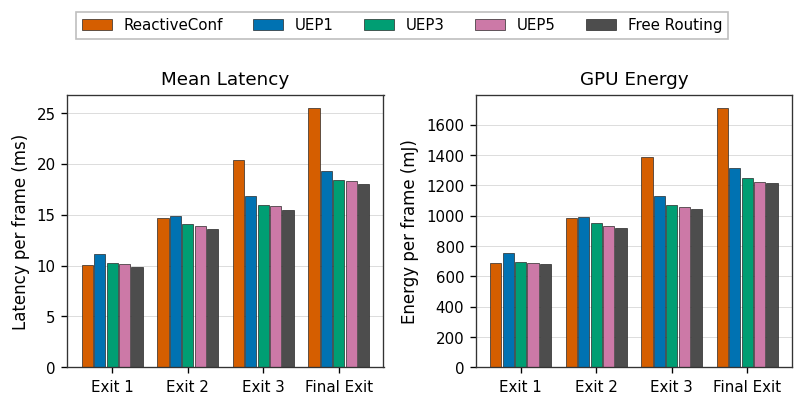

In [19]:
# Figure 1: mean latency and GPU energy per frame, by exit taken.
panels = [('mean', 'Mean Latency', 'Latency per frame (ms)')]
if ENERGY_OK:
    panels.append(('energy', 'GPU Energy', 'Energy per frame (mJ)'))
fig, axes = plt.subplots(1, len(panels), figsize=(6.8 * len(panels) / 2 + 0.6 * (len(panels) == 1), 3.4), squeeze=False)
axes = axes[0]
w = 0.82 / len(METHODS)
xs = np.arange(len(EXIT_ORDER))
for ax, (key, title, ylabel) in zip(axes, panels):
    for i, name in enumerate(METHODS):
        vals = [res[(name, e)][key] for e in EXIT_ORDER]
        ax.bar(xs + (i - (len(METHODS) - 1) / 2) * w, vals, w * 0.9, color=METHOD_COLORS[name],
               edgecolor='#222222', linewidth=0.4, label=name)
    ax.set_xticks(xs); ax.set_xticklabels([EXIT_LABELS[e] for e in EXIT_ORDER])
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.grid(axis='x', visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.legend(handles, labels, loc='upper center', ncol=len(METHODS), bbox_to_anchor=(0.5, 1.0))
savefig(fig, 'fig_latency_energy_per_exit')

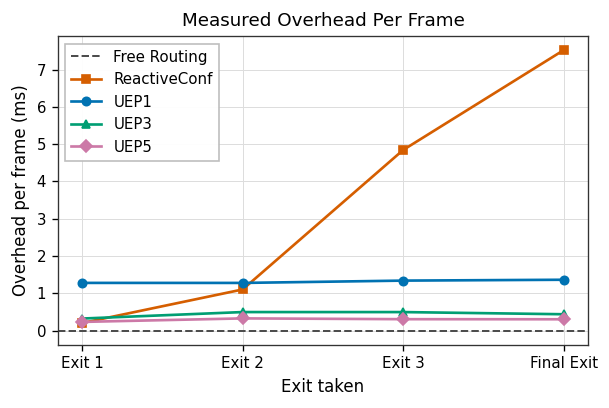

In [20]:
# Figure 2: measured decision overhead per frame, by exit taken.
fig, ax = plt.subplots(figsize=(5.2, 3.5))
ax.axhline(0.0, color=METHOD_COLORS['Free Routing'], ls='--', lw=1.2, label='Free Routing')
for name in [m for m in METHODS if m != 'Free Routing']:
    ax.plot(range(len(EXIT_ORDER)), [res[(name, e)]['overhead'] for e in EXIT_ORDER], color=METHOD_COLORS[name],
            marker=METHOD_MARKERS[name], label=name)
ax.set_xticks(range(len(EXIT_ORDER))); ax.set_xticklabels([EXIT_LABELS[e] for e in EXIT_ORDER])
ax.set_xlabel('Exit taken')
ax.set_ylabel('Overhead per frame (ms)')
ax.set_title('Measured Overhead Per Frame')
ax.legend(loc='upper left')
fig.tight_layout()
savefig(fig, 'fig_measured_overhead_per_frame')

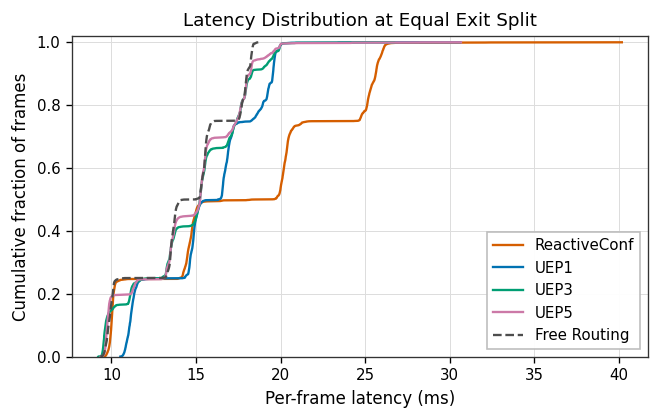

In [21]:
# Figure 3: cumulative latency distribution at the equal exit split (25% of frames per exit).
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for name in METHODS:
    l = np.sort(frames(name)['latency_ms'].to_numpy())
    ax.plot(l, np.arange(1, len(l) + 1) / len(l), color=METHOD_COLORS[name],
            ls='--' if name == 'Free Routing' else '-', lw=1.4, label=name)
ax.set_xlabel('Per-frame latency (ms)')
ax.set_ylabel('Cumulative fraction of frames')
ax.set_ylim(0, 1.02)
ax.set_title('Latency Distribution at Equal Exit Split')
ax.legend(loc='lower right')
fig.tight_layout()
savefig(fig, 'fig_latency_distribution_equal_split')

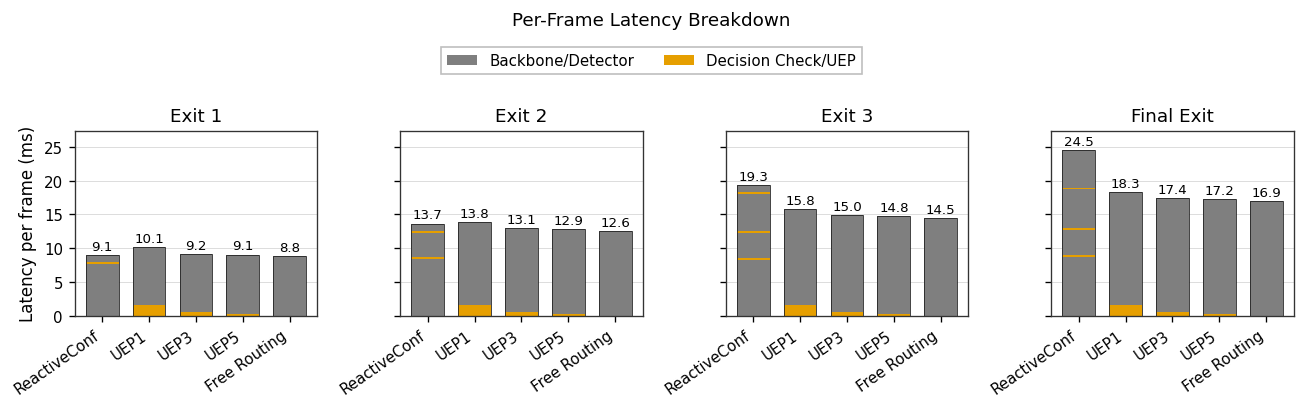

Load + preprocessing (1.05 ms per frame, identical for all methods) is excluded from the bars.


In [22]:
# Figure 4: per-frame latency breakdown, drawn in execution order from the bottom of each bar.
# Load and preprocessing are identical for every method and are excluded. Each bar height equals the measured mean
# latency minus load/preprocessing. Decision segments (UEP pass, or each ReactiveConf confidence check) use the
# profiled block times; the Backbone/Detector segments (trunk, exit heads, NMS) use the profiled block times scaled
# so that the bar matches the measurement.
BB, DEC = 'Backbone/Detector', 'Decision Check/UEP'


def breakdown_segments(name, e):
    method, k = METHOD_SPEC[name]
    C = COMP_LAT
    segs = []
    if method == 'reactiveconf':
        for x in EXIT_ORDER[:EXIT_ORDER.index(e) + 1]:
            if x == 'E1':
                segs.append([BB, C['trunkA'] + C['head:E1']])
            elif x == 'E2':
                segs.append([BB, C['head:E2']])
            elif x == 'E3':
                segs.append([BB, C['trunkB'] + C['head:E3s']])
            else:
                segs.append([BB, C['head:Fs']])
            if x != 'F':
                segs.append([DEC, C[f'check:{x}']])          # sequential confidence check at this exit
        segs.append([BB, C[f'nms:{e}']])                    # NMS at the exit taken
    else:
        if method == 'uep':
            segs.append([DEC, C['uep'] * res[(name, e)]['uep_rate']])   # UEP runs first, before the backbone
        segs.append([BB, C['trunkA'] + (C['trunkB'] if e in ('E3', 'F') else 0.0) + C[f'head:{e}'] + C[f'nms:{e}']])
    merged = []                                              # merge adjacent segments of the same kind
    for comp, v in segs:
        if merged and merged[-1][0] == comp:
            merged[-1][1] += v
        else:
            merged.append([comp, v])
    target = max(res[(name, e)]['mean'] - pre_ms, 0.0)
    dec_sum = sum(v for c, v in merged if c == DEC)
    bb_sum = sum(v for c, v in merged if c == BB)
    scale = max(target - dec_sum, 0.0) / bb_sum if bb_sum > 0 else 0.0
    for sgm in merged:
        if sgm[0] == BB:
            sgm[1] *= scale
    return merged


pre_ms = COMP_LAT['load'] + COMP_LAT['pre']
fig, axes = plt.subplots(1, len(EXIT_ORDER), figsize=(11, 3.4), sharey=True)
breakdown_rows = []
labelled = set()
for ax, e in zip(axes, EXIT_ORDER):
    for i, name in enumerate(METHODS):
        bottom = 0.0
        for j, (comp, v) in enumerate(breakdown_segments(name, e)):
            ax.bar(i, v, 0.7, bottom=bottom, color=COMPONENT_COLORS[comp], edgecolor='none',
                   label=comp if comp not in labelled else None)
            labelled.add(comp)
            breakdown_rows.append({'exit': EXIT_LABELS[e], 'method': name, 'order': j, 'component': comp,
                                   'start_ms': round(bottom, 3), 'ms': round(v, 3)})
            bottom += v
        ax.bar(i, bottom, 0.7, fill=False, edgecolor='#222222', linewidth=0.5)   # outline of the whole bar
        ax.text(i, bottom + 0.3, f'{bottom:.1f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(range(len(METHODS)))
    ax.set_xticklabels(METHODS, rotation=35, ha='right')
    ax.set_title(EXIT_LABELS[e])
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Latency per frame (ms)')
ymax = max(res[(m, e)]['mean'] - pre_ms for m in METHODS for e in EXIT_ORDER)
axes[0].set_ylim(0, ymax * 1.12)
handles, labels = axes[0].get_legend_handles_labels()
order = [labels.index(BB), labels.index(DEC)] if DEC in labels else [labels.index(BB)]
fig.tight_layout(rect=(0, 0, 1, 0.80))
fig.suptitle('Per-Frame Latency Breakdown', y=0.99, fontsize=11)
fig.legend([handles[k] for k in order], [labels[k] for k in order], loc='upper center', ncol=2,
           bbox_to_anchor=(0.5, 0.92))
savefig(fig, 'fig_latency_breakdown')
pd.DataFrame(breakdown_rows).to_csv(TABLE_DIR / 'latency_breakdown.csv', index=False)
print(f'Load + preprocessing ({pre_ms:.2f} ms per frame, identical for all methods) is excluded from the bars.')

## 10. Results table
Per exit and at the equal split. **Overhead** is the latency above Free Routing on the same images. **Δ vs ReactiveConf** is the paired mean latency difference on the same images (negative means faster than ReactiveConf), with a 95% bootstrap confidence interval. GFLOPs and activated parameters are per frame, with the UEP cost amortised over *k* frames. **Wasted GFLOPs** is the computation beyond Free Routing.

In [23]:
rows = []
for gname in GROUPS:
    for name in METHODS:
        r = res[(name, gname)]
        row = {'Exit': GROUP_LABELS[gname], 'Method': name,
               'Mean Latency (ms)': round(r['mean'], 2), 'p99 Latency (ms)': round(r['p99'], 2),
               'Overhead (ms)': round(r['overhead'], 2)}
        if 'delta' in r:
            m, lo, hi = r['delta']
            row['Δ vs ReactiveConf (ms) [95% CI]'] = f'{m:+.2f} [{lo:+.2f}, {hi:+.2f}]'
        else:
            row['Δ vs ReactiveConf (ms) [95% CI]'] = '-'
        if ENERGY_OK:
            row['GPU Energy (mJ)'] = round(r['energy'], 1)
        row['GFLOPs'] = round(r['gflops'], 2)
        row['Wasted GFLOPs'] = round(r['wasted'], 2)
        row['Active Params (M)'] = round(r['params'], 2)
        rows.append(row)
results_table = pd.DataFrame(rows)
results_table.to_csv(TABLE_DIR / 'results_table.csv', index=False)
try:
    (TABLE_DIR / 'results_table.tex').write_text(results_table.to_latex(index=False, escape=True))
except Exception as err:
    print(f'LaTeX export skipped ({err}).')

summary = {
    'created_at': datetime.now(timezone.utc).isoformat(),
    'device': torch.cuda.get_device_name(DEVICE) if HAS_CUDA else 'cpu', 'fp16': USE_HALF, 'execution': ENGINE,
    'model': f'YOLOv8{MODEL_SCALE}, 4 exits, random init + BatchNorm recalibrated on BDD100K',
    'methods': METHODS, 'images_per_exit': int(PER_SET), 'nms_topk': NMS_TOPK, 'nms_topk_source': NMS_TOPK_SOURCE,
    'uep_source': UEP_SOURCE, 'block_gflops': BLOCK_GFLOPS, 'block_params_M': BLOCK_PARAMS, 'block_latency_ms': COMP_LAT,
}
_ = (OUT_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, default=float))
pd.set_option('display.max_columns', 20); pd.set_option('display.width', 250)
display(results_table)

,Exit,Method,Mean Latency (ms),p99 Latency (ms),Overhead (ms),Δ vs ReactiveConf (ms) [95% CI],GPU Energy (mJ),GFLOPs,Wasted GFLOPs,Active Params (M)
0,Exit 1,ReactiveConf,10.10,16.40,0.20,-,689.7,81.13,0.00,22.66
1,Exit 1,UEP1,11.17,12.25,1.28,"+1.08 [+1.02, +1.13]",754.2,81.24,0.11,24.19
2,Exit 1,UEP3,10.22,11.90,0.32,"+0.12 [+0.05, +0.19]",694.9,81.17,0.04,23.17
3,Exit 1,UEP5,10.13,13.14,0.23,"+0.03 [-0.04, +0.10]",691.2,81.16,0.02,22.97
4,Exit 1,Free Routing,9.89,10.46,0.00,"-0.20 [-0.25, -0.16]",681.0,81.13,0.00,22.66
5,Exit 2,ReactiveConf,14.70,17.95,1.10,-,983.6,129.10,6.55,37.08
6,Exit 2,UEP1,14.88,15.48,1.28,"+0.18 [+0.13, +0.22]",990.3,122.66,0.11,35.19
7,Exit 2,UEP3,14.10,15.77,0.50,"-0.61 [-0.68, -0.54]",950.7,122.59,0.04,34.18
8,Exit 2,UEP5,13.93,16.06,0.33,"-0.78 [-0.84, -0.71]",935.2,122.57,0.02,33.98
9,Exit 2,Free Routing,13.60,14.06,0.00,"-1.10 [-1.13, -1.07]",919.6,122.55,0.00,33.67
